In [6]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [13]:
train_df=pd.read_csv("/Users/rahulmanchanda/Desktop/Machine Learning -Credit Card Fraud Detection /data/archive (5)/fraudTrain.csv")
test_df=pd.read_csv("/Users/rahulmanchanda/Desktop/Machine Learning -Credit Card Fraud Detection /data/archive (5)/fraudTest.csv")

In [11]:
train_df.head()

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,...,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,...,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [15]:
test_df.head()

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2020-06-21 12:14:25,2291163933867244,fraud_Kirlin and Sons,personal_care,2.86,Jeff,Elliott,M,351 Darlene Green,...,33.9659,-80.9355,333497,Mechanical engineer,1968-03-19,2da90c7d74bd46a0caf3777415b3ebd3,1371816865,33.986391,-81.200714,0
1,1,2020-06-21 12:14:33,3573030041201292,fraud_Sporer-Keebler,personal_care,29.84,Joanne,Williams,F,3638 Marsh Union,...,40.3207,-110.4360,302,"Sales professional, IT",1990-01-17,324cc204407e99f51b0d6ca0055005e7,1371816873,39.450498,-109.960431,0
2,2,2020-06-21 12:14:53,3598215285024754,"fraud_Swaniawski, Nitzsche and Welch",health_fitness,41.28,Ashley,Lopez,F,9333 Valentine Point,...,40.6729,-73.5365,34496,"Librarian, public",1970-10-21,c81755dbbbea9d5c77f094348a7579be,1371816893,40.495810,-74.196111,0
3,3,2020-06-21 12:15:15,3591919803438423,fraud_Haley Group,misc_pos,60.05,Brian,Williams,M,32941 Krystal Mill Apt. 552,...,28.5697,-80.8191,54767,Set designer,1987-07-25,2159175b9efe66dc301f149d3d5abf8c,1371816915,28.812398,-80.883061,0
4,4,2020-06-21 12:15:17,3526826139003047,fraud_Johnston-Casper,travel,3.19,Nathan,Massey,M,5783 Evan Roads Apt. 465,...,44.2529,-85.0170,1126,Furniture designer,1955-07-06,57ff021bd3f328f8738bb535c302a31b,1371816917,44.959148,-85.884734,0


In [18]:
train_df.shape

(1296675, 23)

In [19]:

test_df.shape

(555719, 23)

In [20]:
print("Training information:")
train_df.info()

Training information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1296675 entries, 0 to 1296674
Data columns (total 23 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   Unnamed: 0             1296675 non-null  int64  
 1   trans_date_trans_time  1296675 non-null  object 
 2   cc_num                 1296675 non-null  int64  
 3   merchant               1296675 non-null  object 
 4   category               1296675 non-null  object 
 5   amt                    1296675 non-null  float64
 6   first                  1296675 non-null  object 
 7   last                   1296675 non-null  object 
 8   gender                 1296675 non-null  object 
 9   street                 1296675 non-null  object 
 10  city                   1296675 non-null  object 
 11  state                  1296675 non-null  object 
 12  zip                    1296675 non-null  int64  
 13  lat                    1296675 non-null  float64
 

In [21]:
print("Testing information:")
test_df.info()

Testing information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 555719 entries, 0 to 555718
Data columns (total 23 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   Unnamed: 0             555719 non-null  int64  
 1   trans_date_trans_time  555719 non-null  object 
 2   cc_num                 555719 non-null  int64  
 3   merchant               555719 non-null  object 
 4   category               555719 non-null  object 
 5   amt                    555719 non-null  float64
 6   first                  555719 non-null  object 
 7   last                   555719 non-null  object 
 8   gender                 555719 non-null  object 
 9   street                 555719 non-null  object 
 10  city                   555719 non-null  object 
 11  state                  555719 non-null  object 
 12  zip                    555719 non-null  int64  
 13  lat                    555719 non-null  float64
 14  long           

In [24]:
print("Training columns:")
print(train_df.columns.tolist())
print("Testing columns:")
print(test_df.columns.tolist())



Training columns:
['Unnamed: 0', 'trans_date_trans_time', 'cc_num', 'merchant', 'category', 'amt', 'first', 'last', 'gender', 'street', 'city', 'state', 'zip', 'lat', 'long', 'city_pop', 'job', 'dob', 'trans_num', 'unix_time', 'merch_lat', 'merch_long', 'is_fraud']
Testing columns:
['Unnamed: 0', 'trans_date_trans_time', 'cc_num', 'merchant', 'category', 'amt', 'first', 'last', 'gender', 'street', 'city', 'state', 'zip', 'lat', 'long', 'city_pop', 'job', 'dob', 'trans_num', 'unix_time', 'merch_lat', 'merch_long', 'is_fraud']


In [25]:
train_df.isna().sum()

Unnamed: 0               0
trans_date_trans_time    0
cc_num                   0
merchant                 0
category                 0
amt                      0
first                    0
last                     0
gender                   0
street                   0
city                     0
state                    0
zip                      0
lat                      0
long                     0
city_pop                 0
job                      0
dob                      0
trans_num                0
unix_time                0
merch_lat                0
merch_long               0
is_fraud                 0
dtype: int64

In [27]:
test_df.isna().sum()

Unnamed: 0               0
trans_date_trans_time    0
cc_num                   0
merchant                 0
category                 0
amt                      0
first                    0
last                     0
gender                   0
street                   0
city                     0
state                    0
zip                      0
lat                      0
long                     0
city_pop                 0
job                      0
dob                      0
trans_num                0
unix_time                0
merch_lat                0
merch_long               0
is_fraud                 0
dtype: int64

In [26]:
train_df.duplicated().sum()

np.int64(0)

In [28]:
test_df.duplicated().sum()

np.int64(0)

In [29]:
train=train_df.drop(columns=["Unnamed: 0"]).copy()

In [30]:
train.head()

,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,Moravian Falls,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,Orient,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,Malad City,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,Boulder,...,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,Doe Hill,...,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [31]:
test=test_df.drop(columns=["Unnamed: 0"]).copy()

In [32]:
test.head()

,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,2020-06-21 12:14:25,2291163933867244,fraud_Kirlin and Sons,personal_care,2.86,Jeff,Elliott,M,351 Darlene Green,Columbia,...,33.9659,-80.9355,333497,Mechanical engineer,1968-03-19,2da90c7d74bd46a0caf3777415b3ebd3,1371816865,33.986391,-81.200714,0
1,2020-06-21 12:14:33,3573030041201292,fraud_Sporer-Keebler,personal_care,29.84,Joanne,Williams,F,3638 Marsh Union,Altonah,...,40.3207,-110.4360,302,"Sales professional, IT",1990-01-17,324cc204407e99f51b0d6ca0055005e7,1371816873,39.450498,-109.960431,0
2,2020-06-21 12:14:53,3598215285024754,"fraud_Swaniawski, Nitzsche and Welch",health_fitness,41.28,Ashley,Lopez,F,9333 Valentine Point,Bellmore,...,40.6729,-73.5365,34496,"Librarian, public",1970-10-21,c81755dbbbea9d5c77f094348a7579be,1371816893,40.495810,-74.196111,0
3,2020-06-21 12:15:15,3591919803438423,fraud_Haley Group,misc_pos,60.05,Brian,Williams,M,32941 Krystal Mill Apt. 552,Titusville,...,28.5697,-80.8191,54767,Set designer,1987-07-25,2159175b9efe66dc301f149d3d5abf8c,1371816915,28.812398,-80.883061,0
4,2020-06-21 12:15:17,3526826139003047,fraud_Johnston-Casper,travel,3.19,Nathan,Massey,M,5783 Evan Roads Apt. 465,Falmouth,...,44.2529,-85.0170,1126,Furniture designer,1955-07-06,57ff021bd3f328f8738bb535c302a31b,1371816917,44.959148,-85.884734,0


In [78]:

target = "is_fraud"


print("Training Dataset - Class Distribution")

print(train[target].value_counts())

print("Training Dataset - percentage Distribution")
print(train[target].value_counts(normalize=True)*100)



Training Dataset - Class Distribution
is_fraud
0    1289169
1       7506
Name: count, dtype: int64
Training Dataset - percentage Distribution
is_fraud
0    99.421135
1     0.578865
Name: proportion, dtype: float64


In [77]:
target = "is_fraud"


print("Testing Dataset - Class Distribution")

print(test[target].value_counts())

print("Testing Dataset - percentage Distribution")
print(test[target].value_counts(normalize=True)*100)

Testing Dataset - Class Distribution
is_fraud
0    553574
1      2145
Name: count, dtype: int64
Testing Dataset - percentage Distribution
is_fraud
0    99.614014
1     0.385986
Name: proportion, dtype: float64


In [ ]:


train["trans_date_trans_time"] = pd.to_datetime(train["trans_date_trans_time"])
test["trans_date_trans_time"] = pd.to_datetime(test["trans_date_trans_time"])

train["dob"] = pd.to_datetime(train["dob"])
test["dob"] = pd.to_datetime(test["dob"])


In [ ]:


train["hour"] = train["trans_date_trans_time"].dt.hour
train["day"] = train["trans_date_trans_time"].dt.day
train["month"] = train["trans_date_trans_time"].dt.month
train["day_of_week"] = train["trans_date_trans_time"].dt.dayofweek

test["hour"] = test["trans_date_trans_time"].dt.hour
test["day"] = test["trans_date_trans_time"].dt.day
test["month"] = test["trans_date_trans_time"].dt.month
test["day_of_week"] = test["trans_date_trans_time"].dt.dayofweek

In [50]:
print("Training Data Date Range:")
print(train["trans_date_trans_time"].min())
print(train["trans_date_trans_time"].max())

print("Testing Data Date Range:")
print(test["trans_date_trans_time"].min())
print(test["trans_date_trans_time"].max())

Training Data Date Range:
2019-01-01 00:00:18
2020-06-21 12:13:37
Testing Data Date Range:
2020-06-21 12:14:25
2020-12-31 23:59:34


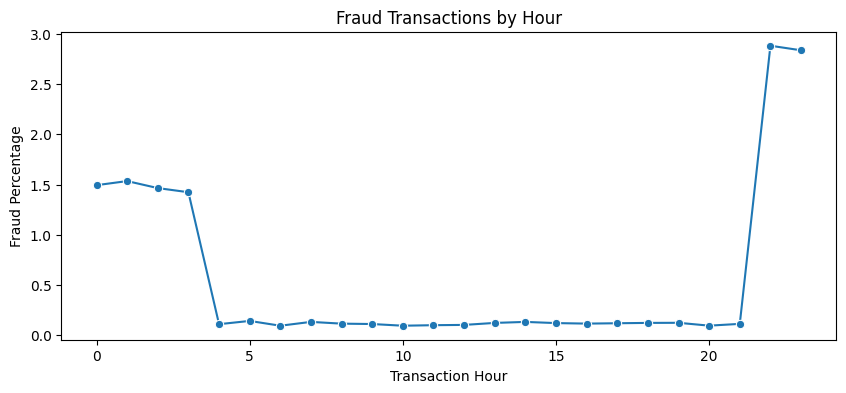

In [53]:
hourly_fraud = train.groupby("hour")["is_fraud"].mean() * 100

plt.figure(figsize=(10, 4))

sns.lineplot(x=hourly_fraud.index, y=hourly_fraud.values, marker="o")

plt.title("Fraud Transactions by Hour")
plt.xlabel("Transaction Hour")
plt.ylabel("Fraud Percentage")


plt.show()

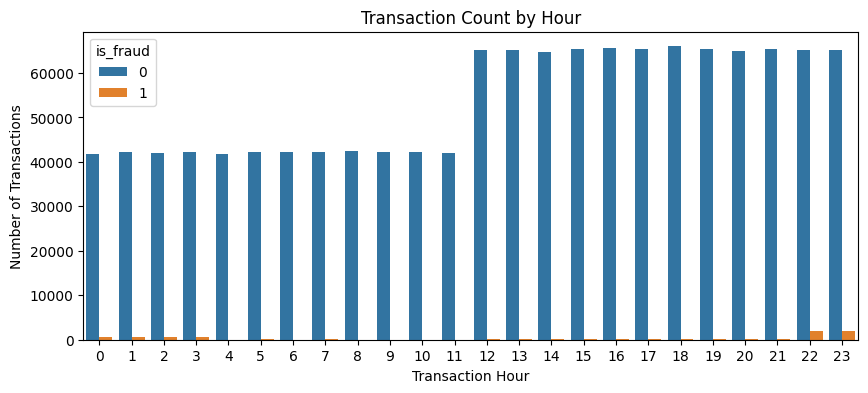

In [54]:
plt.figure(figsize=(10, 4))

sns.countplot(data=train, x="hour", hue="is_fraud")

plt.title("Transaction Count by Hour")
plt.xlabel("Transaction Hour")
plt.ylabel("Number of Transactions")

plt.show()

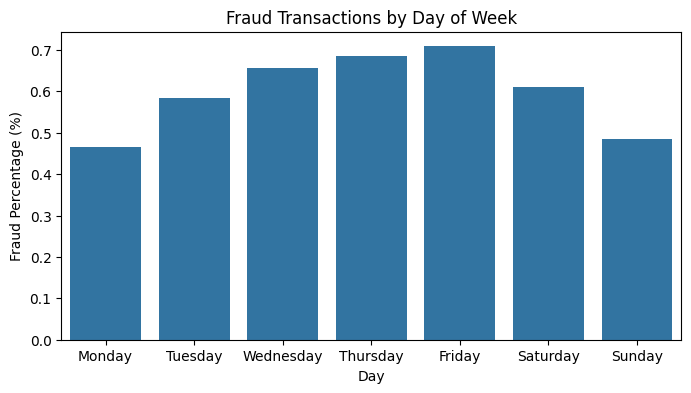

In [63]:


day_names = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

day_fraud = train.groupby("day_of_week")["is_fraud"].mean() * 100

plt.figure(figsize=(8, 4))

sns.barplot(x=day_names, y=day_fraud.values)

plt.title("Fraud Transactions by Day of Week")
plt.xlabel("Day")
plt.ylabel("Fraud Percentage (%)")


plt.show()

In [56]:
print("Transaction Amount Summary")

train.groupby("is_fraud")["amt"].describe()

Transaction Amount Summary


,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,1289169.0,67.667110,154.007971,1.00,9.6100,47.280,82.540,28948.90
1,7506.0,531.320092,390.560070,1.06,245.6625,396.505,900.875,1376.04


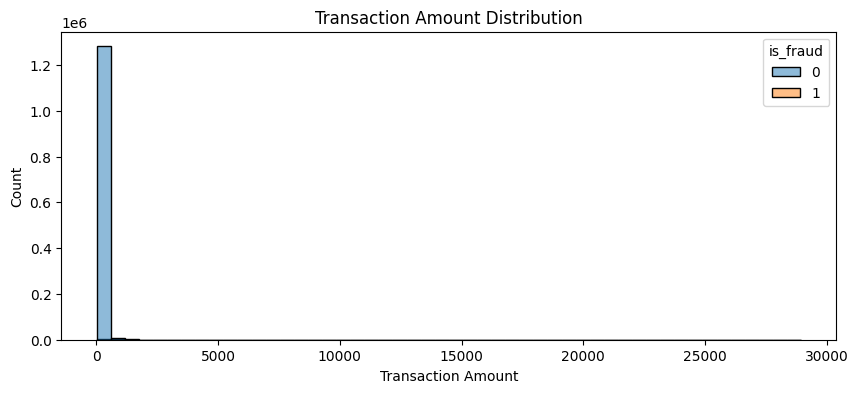

In [60]:
plt.figure(figsize=(10, 4))

sns.histplot(data=train, x="amt", hue="is_fraud",bins=50)

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Count")

plt.show()

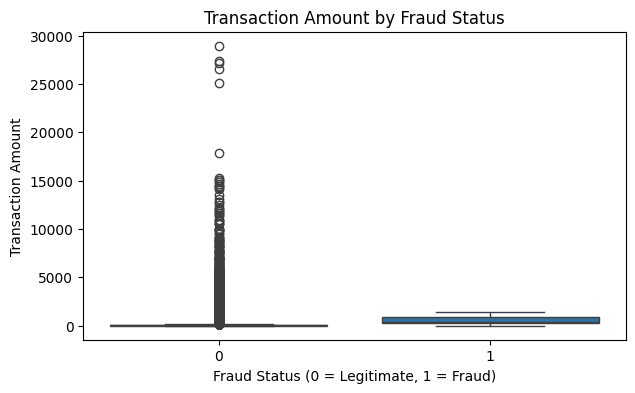

In [61]:
plt.figure(figsize=(7, 4))

sns.boxplot(data=train, x="is_fraud", y="amt")

plt.title("Transaction Amount by Fraud Status")
plt.xlabel("Fraud Status (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Transaction Amount")

plt.show()

In [62]:


category_fraud = train.groupby("category")["is_fraud"].mean() * 100

print("Fraud Percentage by Category:")
print(category_fraud.sort_values(ascending=False))

Fraud Percentage by Category:
category
shopping_net      1.756149
misc_net          1.445795
grocery_pos       1.409761
shopping_pos      0.722538
gas_transport     0.469394
misc_pos          0.313853
grocery_net       0.294817
travel            0.286370
entertainment     0.247835
personal_care     0.242403
kids_pets         0.211439
food_dining       0.165098
home              0.160825
health_fitness    0.154869
Name: is_fraud, dtype: float64


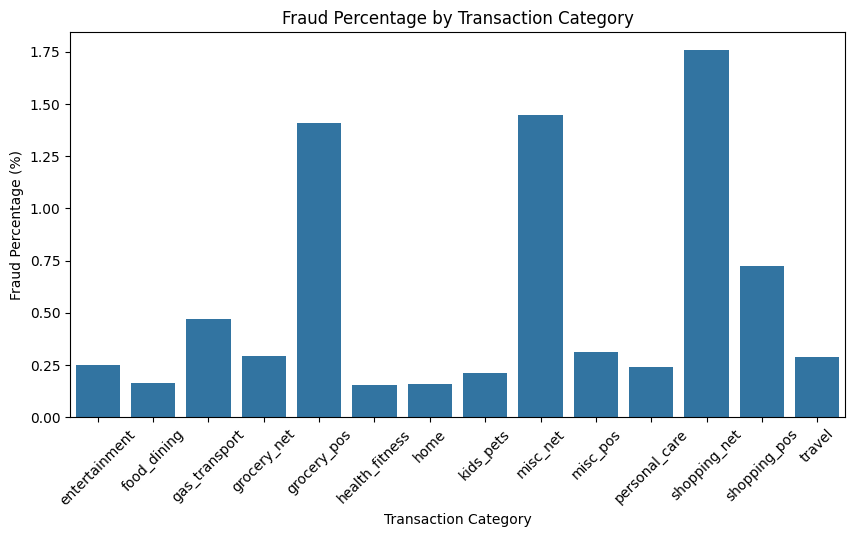

In [65]:
plt.figure(figsize=(10, 5))

sns.barplot(x=category_fraud.index, y=category_fraud.values)

plt.title("Fraud Percentage by Transaction Category")
plt.xlabel("Transaction Category")
plt.ylabel("Fraud Percentage (%)")
plt.xticks(rotation=45)

plt.show()

In [66]:
print("Top 10 Merchants by Transaction Count")

print(train["merchant"].value_counts().head(10))

Top 10 Merchants by Transaction Count
merchant
fraud_Kilback LLC                   4403
fraud_Cormier LLC                   3649
fraud_Schumm PLC                    3634
fraud_Kuhn LLC                      3510
fraud_Boyer PLC                     3493
fraud_Dickinson Ltd                 3434
fraud_Cummerata-Jones               2736
fraud_Kutch LLC                     2734
fraud_Olson, Becker and Koch        2723
fraud_Stroman, Hudson and Erdman    2721
Name: count, dtype: int64


In [68]:
merchant_fraud=train.groupby("merchant")["is_fraud"].mean() * 100

print("Top 10 Merchants by Fraud Percentage")

print(merchant_fraud.sort_values(ascending=False).head(10))

Top 10 Merchants by Fraud Percentage
merchant
fraud_Kozey-Boehm                       2.572347
fraud_Herman, Treutel and Dickens       2.538462
fraud_Kerluke-Abshire                   2.230686
fraud_Brown PLC                         2.210884
fraud_Goyette Inc                       2.161606
fraud_Terry-Huel                        2.154309
fraud_Jast Ltd                          2.150538
fraud_Schmeler, Bashirian and Price     2.083333
fraud_Boyer-Reichert                    1.991614
fraud_Langworth, Boehm and Gulgowski    1.980701
Name: is_fraud, dtype: float64


In [69]:
train["age"] = (train["trans_date_trans_time"] - train["dob"]).dt.days / 365.25

print("Customer Age Summary:")
print(train["age"].describe())

Customer Age Summary:
count    1.296675e+06
mean     4.599640e+01
std      1.739402e+01
min      1.392197e+01
25%      3.259959e+01
50%      4.396988e+01
75%      5.707050e+01
max      9.563860e+01
Name: age, dtype: float64


In [81]:
test["age"] = (test["trans_date_trans_time"] - test["dob"]).dt.days / 365.25
print("Customer Age Summary:")
print(train["age"].describe())

Customer Age Summary:
count    1.296675e+06
mean     4.599640e+01
std      1.739402e+01
min      1.392197e+01
25%      3.259959e+01
50%      4.396988e+01
75%      5.707050e+01
max      9.563860e+01
Name: age, dtype: float64


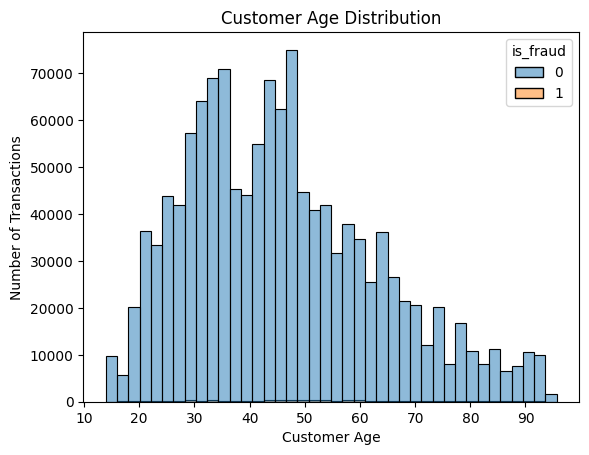

In [71]:
sns.histplot(data=train, x="age", hue="is_fraud", bins=40)

plt.title("Customer Age Distribution")
plt.xlabel("Customer Age")
plt.ylabel("Number of Transactions")

plt.show()

In [79]:
numeric_cols = [
    "amt", "lat", "long", "city_pop",
    "merch_lat", "merch_long", "is_fraud",
    "hour", "day", "month", "day_of_week", "age"
]


numeric_cols = [col for col in numeric_cols if col in train.columns]
corr = train[numeric_cols].corr()

Text(0.5, 1.0, 'Correlation heatmap of selected numeric features')

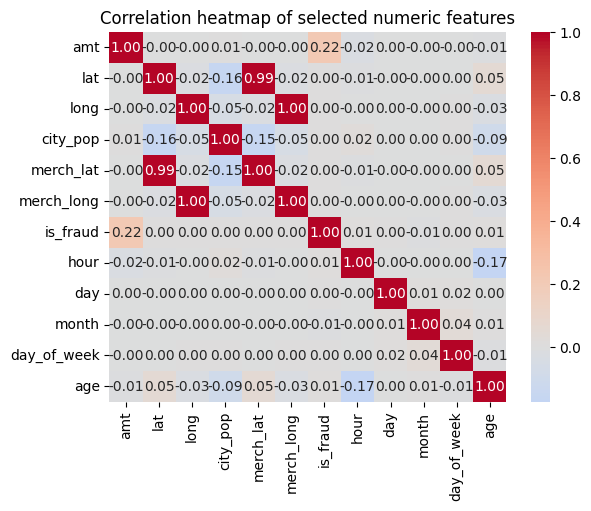

In [80]:
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Correlation heatmap of selected numeric features")